In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Airbnb_Open_Data.xlsx to Airbnb_Open_Data.xlsx


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
df = pd.read_excel("Airbnb_Open_Data.xlsx")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (102599, 26)


,id,NAME,host id,host_identity_verified,host name,neighbourhood group,neighbourhood,lat,long,country,...,service fee,minimum nights,number of reviews,last review,reviews per month,review rate number,calculated host listings count,availability 365,house_rules,license
0,1001254,Clean & quiet apt home by the park,80014485718,unconfirmed,Madaline,Brooklyn,Kensington,40.64749,-73.97237,United States,...,193.0,10.0,9.0,2021-10-19,0.21,4.0,6.0,286.0,Clean up and treat the home the way you'd like...,NaN
1,1002102,Skylit Midtown Castle,52335172823,verified,Jenna,Manhattan,Midtown,40.75362,-73.98377,United States,...,28.0,30.0,45.0,2022-05-21,0.38,4.0,2.0,228.0,Pet friendly but please confirm with me if the...,NaN
2,1002403,THE VILLAGE OF HARLEM....NEW YORK !,78829239556,NaN,Elise,Manhattan,Harlem,40.80902,-73.94190,United States,...,124.0,3.0,0.0,NaT,NaN,5.0,1.0,352.0,"I encourage you to use my kitchen, cooking and...",NaN
3,1002755,NaN,85098326012,unconfirmed,Garry,Brooklyn,Clinton Hill,40.68514,-73.95976,United States,...,74.0,30.0,270.0,2019-07-05,4.64,4.0,1.0,322.0,NaN,NaN
4,1003689,Entire Apt: Spacious Studio/Loft by central park,92037596077,verified,Lyndon,Manhattan,East Harlem,40.79851,-73.94399,United States,...,41.0,10.0,9.0,2018-11-19,0.10,3.0,1.0,289.0,"Please no smoking in the house, porch or on th...",NaN


In [ ]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Number of rows: 102599
Number of columns: 26

Column names:
['id', 'NAME', 'host id', 'host_identity_verified', 'host name', 'neighbourhood group', 'neighbourhood', 'lat', 'long', 'country', 'country code', 'instant_bookable', 'cancellation_policy', 'room type', 'Construction year', 'price', 'service fee', 'minimum nights', 'number of reviews', 'last review', 'reviews per month', 'review rate number', 'calculated host listings count', 'availability 365', 'house_rules', 'license']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 102599 entries, 0 to 102598
Data columns (total 26 columns):
 #   Column                          Non-Null Count   Dtype         
---  ------                          --------------   -----         
 0   id                              102599 non-null  int64         
 1   NAME                            102329 non-null  object        
 2   host id                         102599 non-null  int64         
 3   host_identity_verified          

In [ ]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
display(missing_values.sort_values(ascending=False))

Missing values in each column:


,0
license,102597
house_rules,54843
last review,15893
reviews per month,15879
country,532
availability 365,448
minimum nights,409
host name,408
review rate number,326
calculated host listings count,319


In [ ]:
duplicate_count = df.duplicated().sum()

print("Number of exact duplicate rows:", duplicate_count)

Number of exact duplicate rows: 541


In [ ]:
display(df.describe().T)

,count,mean,min,25%,50%,75%,max,std
id,102599.0,29146234.52213,1001254.0,15085814.5,29136603.0,43201198.0,57367417.0,16257505.607309
host id,102599.0,49254111474.328667,123600518.0,24583328475.0,49117739352.0,73996495817.0,98763129024.0,28538996644.374817
lat,102591.0,40.728094,40.49979,40.68874,40.72229,40.76276,40.91697,0.055857
long,102591.0,-73.949644,-74.24984,-73.98258,-73.95444,-73.93235,-73.70522,0.049521
instant_bookable,102494.0,0.497785,0.0,0.0,0.0,1.0,1.0,0.499998
Construction year,102385.0,2012.487464,2003.0,2007.0,2012.0,2017.0,2022.0,5.765556
price,102352.0,625.293536,50.0,340.0,624.0,913.0,1200.0,331.671614
service fee,102326.0,125.026924,10.0,68.0,125.0,183.0,240.0,66.325739
minimum nights,102190.0,8.135845,-1223.0,2.0,3.0,5.0,5645.0,30.553781
number of reviews,102416.0,27.483743,0.0,1.0,7.0,30.0,1024.0,49.508954


In [ ]:
# Count missing values in each column
missing_count = df.isnull().sum()

# Calculate percentage of missing values
missing_percentage = (df.isnull().mean() * 100).round(2)

# Combine both results into one table
missing_report = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percentage
})

# Show columns with missing values first
missing_report = missing_report.sort_values(
    by="Missing Percentage",
    ascending=False
)

display(missing_report)

,Missing Count,Missing Percentage
license,102597,100.00
house_rules,54843,53.45
last review,15893,15.49
reviews per month,15879,15.48
country,532,0.52
availability 365,448,0.44
minimum nights,409,0.40
host name,408,0.40
review rate number,326,0.32
calculated host listings count,319,0.31


In [ ]:
# Count unique listing IDs
print("Unique listing IDs:", df["id"].nunique())

# Count rows with repeated listing IDs
print("Rows with repeated IDs:", df["id"].duplicated().sum())

# Display examples of repeated IDs
repeated_id_rows = df[
    df["id"].duplicated(keep=False)
].sort_values("id")

display(repeated_id_rows.head(10))

Unique listing IDs: 102058
Rows with repeated IDs: 541


,id,NAME,host id,host_identity_verified,host name,neighbourhood group,neighbourhood,lat,long,country,...,service fee,minimum nights,number of reviews,last review,reviews per month,review rate number,calculated host listings count,availability 365,house_rules,license
9098,6026161,Upper East Side 2 bedroom- close to Hospitals-,65193709566,verified,Juliana,Manhattan,Upper East Side,40.76222,-73.96030,United States,...,21.0,30.0,2.0,2019-06-08,0.21,3.0,34.0,157.0,NaN,NaN
102474,6026161,Upper East Side 2 bedroom- close to Hospitals-,65193709566,verified,Juliana,Manhattan,Upper East Side,40.76222,-73.96030,United States,...,21.0,30.0,2.0,2019-06-08,0.21,3.0,34.0,157.0,NaN,NaN
102475,6026714,Close to East Side Hospitals- Modern 2 Bedroom...,31072202372,verified,Juliana,Manhattan,Upper East Side,40.76249,-73.96217,United States,...,57.0,30.0,6.0,2019-01-31,0.14,3.0,34.0,67.0,"The quieter the better, but otherwise make you...",NaN
9099,6026714,Close to East Side Hospitals- Modern 2 Bedroom...,31072202372,verified,Juliana,Manhattan,Upper East Side,40.76249,-73.96217,United States,...,57.0,30.0,6.0,2019-01-31,0.14,3.0,34.0,67.0,"The quieter the better, but otherwise make you...",NaN
9100,6027266,ACADIA Spacious 2 Bedroom Apt - Close to Hospi...,95854111798,verified,Juliana,Manhattan,Upper East Side,40.76021,-73.96157,United States,...,117.0,30.0,10.0,2018-11-18,0.22,5.0,34.0,211.0,No Smoking No Pets,NaN
102476,6027266,ACADIA Spacious 2 Bedroom Apt - Close to Hospi...,95854111798,verified,Juliana,Manhattan,Upper East Side,40.76021,-73.96157,United States,...,117.0,30.0,10.0,2018-11-18,0.22,5.0,34.0,211.0,No Smoking No Pets,NaN
102477,6027818,*ENCHANTMENT* Upper East Side 2 bedroom- Sunny!,73401481508,unconfirmed,Juliana,Manhattan,Upper East Side,40.76244,-73.96031,United States,...,108.0,30.0,9.0,2018-09-30,0.20,5.0,34.0,411.0,Please treat it as it were your own home and b...,NaN
9101,6027818,*ENCHANTMENT* Upper East Side 2 bedroom- Sunny!,73401481508,unconfirmed,Juliana,Manhattan,Upper East Side,40.76244,-73.96031,United States,...,108.0,30.0,9.0,2018-09-30,0.20,5.0,34.0,411.0,Please treat it as it were your own home and b...,NaN
9102,6028371,*JAMES* Amazing Spacious 2 Bedroom- Bright!,37678424985,verified,Juliana,Manhattan,Upper East Side,40.76035,-73.96133,United States,...,161.0,30.0,8.0,2019-06-11,0.27,4.0,34.0,411.0,Be courteous and respectful to people in the h...,NaN
102478,6028371,*JAMES* Amazing Spacious 2 Bedroom- Bright!,37678424985,verified,Juliana,Manhattan,Upper East Side,40.76035,-73.96133,United States,...,161.0,30.0,8.0,2019-06-11,0.27,4.0,34.0,411.0,Be courteous and respectful to people in the h...,NaN


In [ ]:
# Summary of selected numerical columns
numeric_columns = [
    "price",
    "minimum nights",
    "number of reviews",
    "reviews per month",
    "review rate number",
    "availability 365"
]

display(df[numeric_columns].describe().T)

,count,mean,std,min,25%,50%,75%,max
price,102352.0,625.293536,331.671614,50.00,340.00,624.00,913.0,1200.0
minimum nights,102190.0,8.135845,30.553781,-1223.00,2.00,3.00,5.0,5645.0
number of reviews,102416.0,27.483743,49.508954,0.00,1.00,7.00,30.0,1024.0
reviews per month,86720.0,1.374022,1.746621,0.01,0.22,0.74,2.0,90.0
review rate number,102273.0,3.279106,1.284657,1.00,2.00,3.00,4.0,5.0
availability 365,102151.0,141.133254,135.435024,-10.00,3.00,96.00,269.0,3677.0


In [ ]:
# 1. Count exact duplicate rows
exact_duplicates = df.duplicated().sum()

# 2. Check whether repeated IDs occur in different records
repeated_ids = df[df["id"].duplicated(keep=False)]

print("Exact duplicate rows:", exact_duplicates)
print("Rows belonging to repeated IDs:", len(repeated_ids))
print("Unique repeated IDs:", repeated_ids["id"].nunique())

# 3. Inspect one repeated listing
sample_id = repeated_ids["id"].iloc[0]

display(
    df[df["id"] == sample_id]
)

Exact duplicate rows: 541
Rows belonging to repeated IDs: 1082
Unique repeated IDs: 541


,id,NAME,host id,host_identity_verified,host name,neighbourhood group,neighbourhood,lat,long,country,...,service fee,minimum nights,number of reviews,last review,reviews per month,review rate number,calculated host listings count,availability 365,house_rules,license
9098,6026161,Upper East Side 2 bedroom- close to Hospitals-,65193709566,verified,Juliana,Manhattan,Upper East Side,40.76222,-73.9603,United States,...,21.0,30.0,2.0,2019-06-08,0.21,3.0,34.0,157.0,NaN,NaN
102474,6026161,Upper East Side 2 bedroom- close to Hospitals-,65193709566,verified,Juliana,Manhattan,Upper East Side,40.76222,-73.9603,United States,...,21.0,30.0,2.0,2019-06-08,0.21,3.0,34.0,157.0,NaN,NaN


In [ ]:
# Investigate minimum nights outside the plausible range
invalid_nights = df[
    (df["minimum nights"] < 1) |
    (df["minimum nights"] > 365)
]

print("Invalid minimum-night records:", len(invalid_nights))

display(
    invalid_nights[
        ["id", "NAME", "minimum nights", "price", "room type"]
    ].head(15)
)

# Investigate availability outside 0–365
invalid_availability = df[
    (df["availability 365"] < 0) |
    (df["availability 365"] > 365)
]

print("Invalid availability records:", len(invalid_availability))

display(
    invalid_availability[
        ["id", "NAME", "availability 365", "neighbourhood"]
    ].head(15)
)

Invalid minimum-night records: 48


,id,NAME,minimum nights,price,room type
167,1093570,Convenient cozy cheap apt Manhattan,371.0,375.0,Entire home/apt
176,1098541,BROOKLYN VICTORIAN STYLE SUITE.....,-10.0,1155.0,Private room
186,1104064,SAFE AND BEAUTIFUL ACCOMODATION,366.0,946.0,Private room
263,1146591,"Private, Large & Sunny Top Floor Apt w/W&D",399.0,841.0,Entire home/apt
299,1166474,Bright Beautiful Brooklyn,452.0,614.0,Private room
350,1194641,LARGE 1BR (CONV 2BR) CROWN HEIGHTS,3455.0,1142.0,Entire home/apt
352,1195746,"Beautiful, Brightâ€™s, Warm & Spacious 1.5BR Apt",-5.0,73.0,Entire home/apt
398,1221151,SUPER BIG AND COZY PRIVATE BEDROOM,-1.0,779.0,Private room
421,1233854,Charming Nolita Apartment!!,-10.0,874.0,Entire home/apt
441,1244900,Cozy apartment in a brownstone,-12.0,920.0,Entire home/apt


Invalid availability records: 3214


,id,NAME,availability 365,neighbourhood
5,1004098,Large Cozy 1 BR Apartment In Midtown East,374.0,Murray Hill
9,1006307,Cozy Clean Guest Room - Family Apt,375.0,Upper West Side
25,1015144,"MAISON DES SIRENES1,bohemian apartment",372.0,Bedford-Stuyvesant
33,1019562,Loft in Williamsburg Area w/ Roof,383.0,Greenpoint
34,1020114,back room/bunk beds,411.0,Harlem
36,1021219,"Lovely room 2 & garden; Best area, Legal rental",416.0,South Slope
43,1025085,1bdr w private bath. in lofty apt,405.0,Fort Greene
103,1058223,Monkey Retreat Manhattan,393.0,Washington Heights
110,1062089,Sunny 2-story Brooklyn townhouse w deck and ga...,400.0,Gowanus
115,1064851,2 BR / 2 Bath Duplex Apt with patio! East Village,417.0,East Village


In [ ]:
quality_report = pd.DataFrame({
    "column": df.columns,
    "data_type": df.dtypes.astype(str).values,
    "missing_count": df.isnull().sum().values,
    "missing_percentage": (
        df.isnull().mean().mul(100).round(2).values
    ),
    "unique_values": df.nunique(dropna=True).values
})

display(
    quality_report.sort_values(
        "missing_percentage",
        ascending=False
    )
)

,column,data_type,missing_count,missing_percentage,unique_values
25,license,object,102597,100.00,1
24,house_rules,object,54843,53.45,1975
19,last review,datetime64[ns],15893,15.49,2477
20,reviews per month,float64,15879,15.48,1016
9,country,object,532,0.52,1
23,availability 365,float64,448,0.44,438
17,minimum nights,float64,409,0.40,153
4,host name,object,408,0.40,13189
21,review rate number,float64,326,0.32,5
22,calculated host listings count,float64,319,0.31,78


In [ ]:
quality_report.to_csv(
    "airbnb_data_quality_report.csv",
    index=False
)

print("Data-quality report saved successfully!")

Data-quality report saved successfully!


In [ ]:
from google.colab import files

files.download("airbnb_data_quality_report.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Count how many times each listing ID appears
id_counts = df["id"].value_counts()

# Keep only IDs that appear more than once
repeated_id_counts = id_counts[id_counts > 1]

print("Number of repeated IDs:", len(repeated_id_counts))
print("Total rows belonging to repeated IDs:", repeated_id_counts.sum())

# Count IDs that appear exactly twice
print(
    "IDs appearing exactly twice:",
    (repeated_id_counts == 2).sum()
)

# Count IDs appearing more than twice
print(
    "IDs appearing more than twice:",
    (repeated_id_counts > 2).sum()
)

Number of repeated IDs: 541
Total rows belonging to repeated IDs: 1082
IDs appearing exactly twice: 541
IDs appearing more than twice: 0


In [ ]:
# Create a copy of the original dataset
df_clean = df.copy()

# Store the original number of rows
rows_before = len(df_clean)

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates()

# Store the number of rows after removing duplicates
rows_after = len(df_clean)

# Display the results
print("Rows before cleaning:", rows_before)
print("Rows after cleaning:", rows_after)
print("Duplicate rows removed:", rows_before - rows_after)
print("Remaining exact duplicates:", df_clean.duplicated().sum())

Rows before cleaning: 102599
Rows after cleaning: 102058
Duplicate rows removed: 541
Remaining exact duplicates: 0


In [ ]:
# Import the regular expression library
import re

# Create a copy of our deduplicated dataset
df_clean = df_clean.copy()

# Standardize column names
df_clean.columns = [
    re.sub(r"_+", "_", re.sub(r"[^a-z0-9]+", "_", col.lower())).strip("_")
    for col in df_clean.columns
]

# Display the updated column names
print(df_clean.columns.tolist())

['id', 'name', 'host_id', 'host_identity_verified', 'host_name', 'neighbourhood_group', 'neighbourhood', 'lat', 'long', 'country', 'country_code', 'instant_bookable', 'cancellation_policy', 'room_type', 'construction_year', 'price', 'service_fee', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'review_rate_number', 'calculated_host_listings_count', 'availability_365', 'house_rules', 'license']


In [ ]:
print("Dataset shape:", df_clean.shape)
print("\nColumn names:")
print(df_clean.columns.tolist())

print("\nRemaining exact duplicates:", df_clean.duplicated().sum())

Dataset shape: (102058, 26)

Column names:
['id', 'name', 'host_id', 'host_identity_verified', 'host_name', 'neighbourhood_group', 'neighbourhood', 'lat', 'long', 'country', 'country_code', 'instant_bookable', 'cancellation_policy', 'room_type', 'construction_year', 'price', 'service_fee', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'review_rate_number', 'calculated_host_listings_count', 'availability_365', 'house_rules', 'license']

Remaining exact duplicates: 0


In [ ]:
# Check minimum-night values
print("Minimum nights below 1:",
      (df_clean["minimum_nights"] < 1).sum())

print("Minimum nights above 365:",
      (df_clean["minimum_nights"] > 365).sum())

# Check availability values
print("Availability below 0:",
      (df_clean["availability_365"] < 0).sum())

print("Availability above 365:",
      (df_clean["availability_365"] > 365).sum())

# Check prices
print("Prices less than or equal to zero:",
      (df_clean["price"] <= 0).sum())

print("Missing prices:",
      df_clean["price"].isna().sum())

Minimum nights below 1: 13
Minimum nights above 365: 35
Availability below 0: 431
Availability above 365: 2754
Prices less than or equal to zero: 0
Missing prices: 247


In [ ]:
# Show listings with suspicious minimum nights
print("Minimum nights below 1:")
display(df_clean[df_clean["minimum_nights"] < 1][
    ["id", "neighbourhood", "room_type", "minimum_nights", "price"]
].head(10))

print("Minimum nights above 365:")
display(df_clean[df_clean["minimum_nights"] > 365][
    ["id", "neighbourhood", "room_type", "minimum_nights", "price"]
].head(10))

# Show listings with suspicious availability
print("Availability below 0:")
display(df_clean[df_clean["availability_365"] < 0][
    ["id", "neighbourhood", "room_type", "availability_365", "price"]
].head(10))

print("Availability above 365:")
display(df_clean[df_clean["availability_365"] > 365][
    ["id", "neighbourhood", "room_type", "availability_365", "price"]
].head(10))

Minimum nights below 1:


,id,neighbourhood,room_type,minimum_nights,price
176,1098541,Fort Greene,Private room,-10.0,1155.0
352,1195746,Crown Heights,Entire home/apt,-5.0,73.0
398,1221151,Kensington,Private room,-1.0,779.0
421,1233854,Nolita,Entire home/apt,-10.0,874.0
441,1244900,Harlem,Entire home/apt,-12.0,920.0
478,1265335,Upper West Side,Entire home/apt,-2.0,410.0
525,1291294,Bedford-Stuyvesant,Entire home/apt,-3.0,413.0
42446,24444262,Hunts Point,Private room,-1223.0,1200.0
42500,24474086,Hell's Kitchen,Entire home/apt,-365.0,711.0
42538,24495073,Bedford-Stuyvesant,Entire home/apt,-200.0,85.0


Minimum nights above 365:


,id,neighbourhood,room_type,minimum_nights,price
167,1093570,Harlem,Entire home/apt,371.0,375.0
186,1104064,Bedford-Stuyvesant,Private room,366.0,946.0
263,1146591,Bedford-Stuyvesant,Entire home/apt,399.0,841.0
299,1166474,Greenpoint,Private room,452.0,614.0
350,1194641,Crown Heights,Entire home/apt,3455.0,1142.0
473,1262574,Washington Heights,Private room,398.0,409.0
1306,1722640,Bushwick,Entire home/apt,370.0,1179.0
2855,2578153,Battery Park City,Entire home/apt,1000.0,198.0
5768,4187002,Greenwich Village,Entire home/apt,1250.0,379.0
7356,5064055,Long Island City,Entire home/apt,500.0,129.0


Availability below 0:


,id,neighbourhood,room_type,availability_365,price
139,1078106,Bedford-Stuyvesant,Entire home/apt,-10.0,593.0
142,1079763,Williamsburg,Entire home/apt,-2.0,658.0
170,1095227,St. George,Private room,-1.0,1015.0
236,1131679,East Harlem,Entire home/apt,-6.0,1052.0
251,1139963,Tompkinsville,Private room,-1.0,784.0
308,1171444,West Village,Entire home/apt,-9.0,935.0
355,1197403,Clinton Hill,Private room,-9.0,643.0
462,1256499,Crown Heights,Entire home/apt,-4.0,293.0
476,1264231,Park Slope,Entire home/apt,-4.0,455.0
477,1264783,Park Slope,Private room,-6.0,563.0


Availability above 365:


,id,neighbourhood,room_type,availability_365,price
5,1004098,Murray Hill,Entire home/apt,374.0,577.0
9,1006307,Upper West Side,Private room,375.0,291.0
25,1015144,Bedford-Stuyvesant,Entire home/apt,372.0,1175.0
33,1019562,Greenpoint,Private room,383.0,858.0
34,1020114,Harlem,Private room,411.0,545.0
36,1021219,South Slope,Private room,416.0,1111.0
43,1025085,Fort Greene,Private room,405.0,687.0
103,1058223,Washington Heights,Private room,393.0,306.0
110,1062089,Gowanus,Entire home/apt,400.0,528.0
115,1064851,East Village,Entire home/apt,417.0,677.0


In [ ]:
# 1. Create flags so we can track suspicious values
df_clean["minimum_nights_invalid_low"] = (
    df_clean["minimum_nights"] < 1
)

df_clean["minimum_nights_over_365_flag"] = (
    df_clean["minimum_nights"] > 365
)

df_clean["availability_invalid_flag"] = (
    df_clean["availability_365"].notna()
    & ~df_clean["availability_365"].between(0, 365)
)

# 2. Replace invalid values with NaN (missing values)
df_clean.loc[
    df_clean["minimum_nights"] < 1,
    "minimum_nights"
] = np.nan

df_clean.loc[
    df_clean["availability_invalid_flag"],
    "availability_365"
] = np.nan

# 3. Check the results
print("Rows after duplicate removal:", len(df_clean))

print(
    "Missing minimum nights after cleaning:",
    df_clean["minimum_nights"].isna().sum()
)

print(
    "Minimum nights above 365 (flagged for review):",
    df_clean["minimum_nights_over_365_flag"].sum()
)

print(
    "Missing availability after cleaning:",
    df_clean["availability_365"].isna().sum()
)

print(
    "Invalid availability remaining:",
    (
        df_clean["availability_365"].notna()
        & ~df_clean["availability_365"].between(0, 365)
    ).sum()
)

Rows after duplicate removal: 102058
Missing minimum nights after cleaning: 413
Minimum nights above 365 (flagged for review): 35
Missing availability after cleaning: 3633
Invalid availability remaining: 0


In [ ]:
# Count listings with zero reviews
zero_reviews = df_clean["number_of_reviews"] == 0

print("Listings with zero reviews:", zero_reviews.sum())

# Missing review dates
print(
    "Missing last review:",
    df_clean["last_review"].isna().sum()
)

print(
    "Missing last review among zero-review listings:",
    (zero_reviews & df_clean["last_review"].isna()).sum()
)

# Missing monthly review rates
print(
    "Missing reviews per month:",
    df_clean["reviews_per_month"].isna().sum()
)

print(
    "Missing monthly rate among zero-review listings:",
    (zero_reviews & df_clean["reviews_per_month"].isna()).sum()
)

# Check whether any listings with reviews still lack review information
print(
    "Missing last review despite having reviews:",
    (
        (df_clean["number_of_reviews"] > 0)
        & df_clean["last_review"].isna()
    ).sum()
)

print(
    "Missing monthly rate despite having reviews:",
    (
        (df_clean["number_of_reviews"] > 0)
        & df_clean["reviews_per_month"].isna()
    ).sum()
)

Listings with zero reviews: 15673
Missing last review: 15832
Missing last review among zero-review listings: 15673
Missing reviews per month: 15818
Missing monthly rate among zero-review listings: 15673
Missing last review despite having reviews: 35
Missing monthly rate despite having reviews: 22


In [ ]:
# Display the data type of every column
print(df_clean.dtypes)

# Count columns by data type
print("\nData type summary:")
print(df_clean.dtypes.value_counts())

# Convert last_review to a proper date format
df_clean["last_review"] = pd.to_datetime(
    df_clean["last_review"],
    errors="coerce"
)

# Verify the date conversion
print("\nLast review data type:")
print(df_clean["last_review"].dtype)

id                                         int64
name                                      object
host_id                                    int64
host_identity_verified                    object
host_name                                 object
neighbourhood_group                       object
neighbourhood                             object
lat                                      float64
long                                     float64
country                                   object
country_code                              object
instant_bookable                         float64
cancellation_policy                       object
room_type                                 object
construction_year                        float64
price                                    float64
service_fee                              float64
minimum_nights                           float64
number_of_reviews                        float64
last_review                       datetime64[ns]
reviews_per_month   

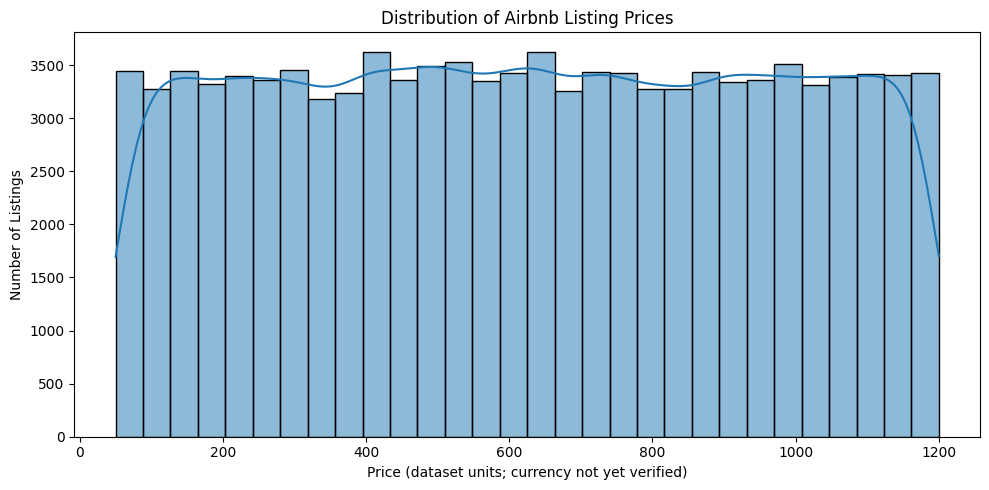

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean,
    x="price",
    bins=30,
    kde=True
)

plt.title("Distribution of Airbnb Listing Prices")
plt.xlabel("Price (dataset units; currency not yet verified)")
plt.ylabel("Number of Listings")
plt.tight_layout()
plt.show()

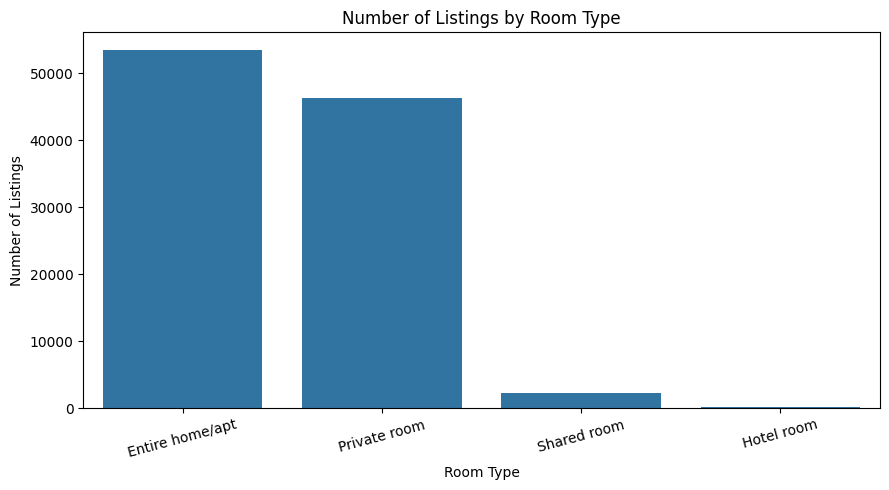

In [ ]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df_clean,
    x="room_type",
    order=df_clean["room_type"].value_counts().index
)

plt.title("Number of Listings by Room Type")
plt.xlabel("Room Type")
plt.ylabel("Number of Listings")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

room_type
Hotel room         666.391304
Shared room        634.828182
Entire home/apt    625.240056
Private room       624.935628
Name: price, dtype: float64


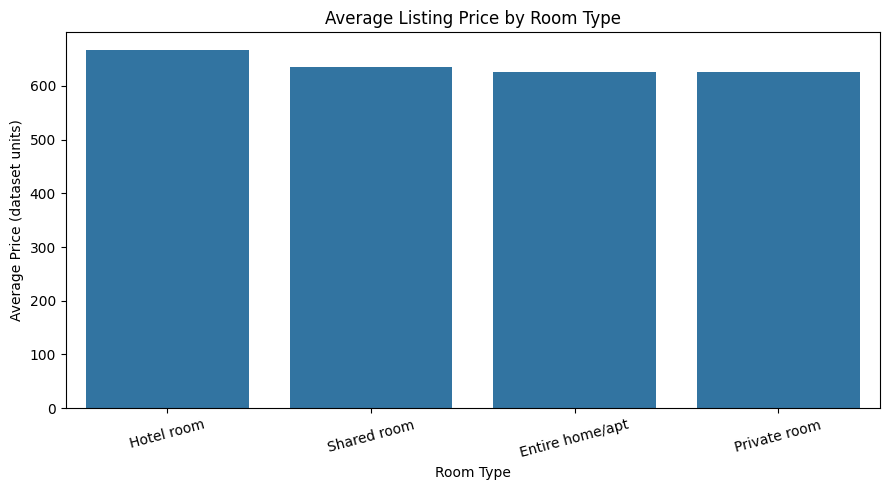

In [ ]:
avg_price = (
    df_clean.groupby("room_type")["price"]
    .mean()
    .sort_values(ascending=False)
)

print(avg_price)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=avg_price.index,
    y=avg_price.values
)

plt.title("Average Listing Price by Room Type")
plt.xlabel("Room Type")
plt.ylabel("Average Price (dataset units)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [ ]:
# Calculate price statistics for each room type
room_price_summary = (
    df_clean.groupby("room_type")["price"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
    .sort_values("median", ascending=False)
)

display(room_price_summary)

,count,mean,median,std
room_type,,,,
Shared room,2200,634.83,651.5,338.41
Hotel room,115,666.39,643.0,311.42
Entire home/apt,53296,625.24,624.0,331.70
Private room,46200,624.94,623.0,331.36


In [ ]:
# Count listings in each neighbourhood group
print("Listings by neighbourhood group:")
display(
    df_clean["neighbourhood_group"]
    .value_counts(dropna=False)
)

# Calculate price statistics by neighbourhood group
neighbourhood_price = (
    df_clean.groupby("neighbourhood_group", dropna=False)["price"]
    .agg(["count", "mean", "median"])
    .round(2)
    .sort_values("median", ascending=False)
)

print("Price statistics by neighbourhood group:")
display(neighbourhood_price)

Listings by neighbourhood group:


,count
neighbourhood_group,
Manhattan,43557
Brooklyn,41630
Queens,13197
Bronx,2694
Staten Island,949
NaN,29
manhatan,1
brookln,1


Price statistics by neighbourhood group:


,count,mean,median
neighbourhood_group,,,
NaN,28,658.36,661.0
Bronx,2687,627.76,632.0
Staten Island,946,623.99,628.0
Queens,13164,630.22,628.0
Brooklyn,41537,626.50,626.0
Manhattan,43447,622.65,621.0
brookln,1,580.00,580.0
manhatan,1,460.00,460.0


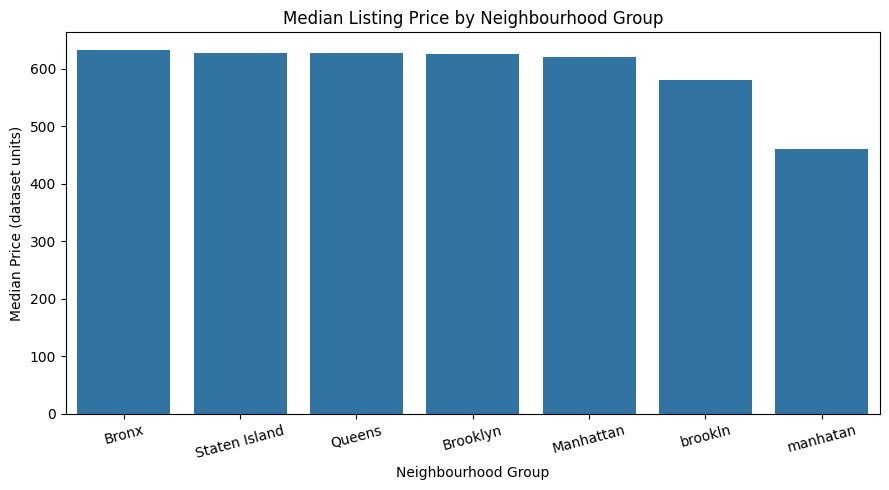

In [ ]:
# Calculate median price for each neighbourhood group
median_prices = (
    df_clean.groupby("neighbourhood_group")["price"]
    .median()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=median_prices.index,
    y=median_prices.values
)

plt.title("Median Listing Price by Neighbourhood Group")
plt.xlabel("Neighbourhood Group")
plt.ylabel("Median Price (dataset units)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [ ]:
# Standardize neighbourhood group spelling
df_clean["neighbourhood_group"] = (
    df_clean["neighbourhood_group"]
    .replace({
        "brookln": "Brooklyn",
        "manhatan": "Manhattan"
    })
)

# Check the cleaned categories
print("Neighbourhood groups after standardization:")
display(
    df_clean["neighbourhood_group"]
    .value_counts(dropna=False)
)

Neighbourhood groups after standardization:


,count
neighbourhood_group,
Manhattan,43558
Brooklyn,41631
Queens,13197
Bronx,2694
Staten Island,949
NaN,29


In [ ]:
neighbourhood_price = (
    df_clean.groupby("neighbourhood_group", dropna=False)["price"]
    .agg(["count", "mean", "median"])
    .round(2)
    .sort_values("median", ascending=False)
)

display(neighbourhood_price)

,count,mean,median
neighbourhood_group,,,
NaN,28,658.36,661.0
Bronx,2687,627.76,632.0
Staten Island,946,623.99,628.0
Queens,13164,630.22,628.0
Brooklyn,41538,626.50,626.0
Manhattan,43448,622.65,621.0


In [ ]:
# Select useful numerical columns for correlation analysis
numeric_cols = [
    "price",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "review_rate_number",
    "calculated_host_listings_count",
    "availability_365",
    "construction_year"
]

# Calculate correlations between numerical columns
correlation_matrix = df_clean[numeric_cols].corr()

# Display correlations with price, from highest to lowest
price_correlation = (
    correlation_matrix["price"]
    .drop("price")
    .sort_values(ascending=False)
)

print("Correlation of numerical features with price:")
display(price_correlation.round(3))

Correlation of numerical features with price:


,price
number_of_reviews,0.005
reviews_per_month,0.004
calculated_host_listings_count,-0.000
availability_365,-0.002
minimum_nights,-0.003
construction_year,-0.004
review_rate_number,-0.005


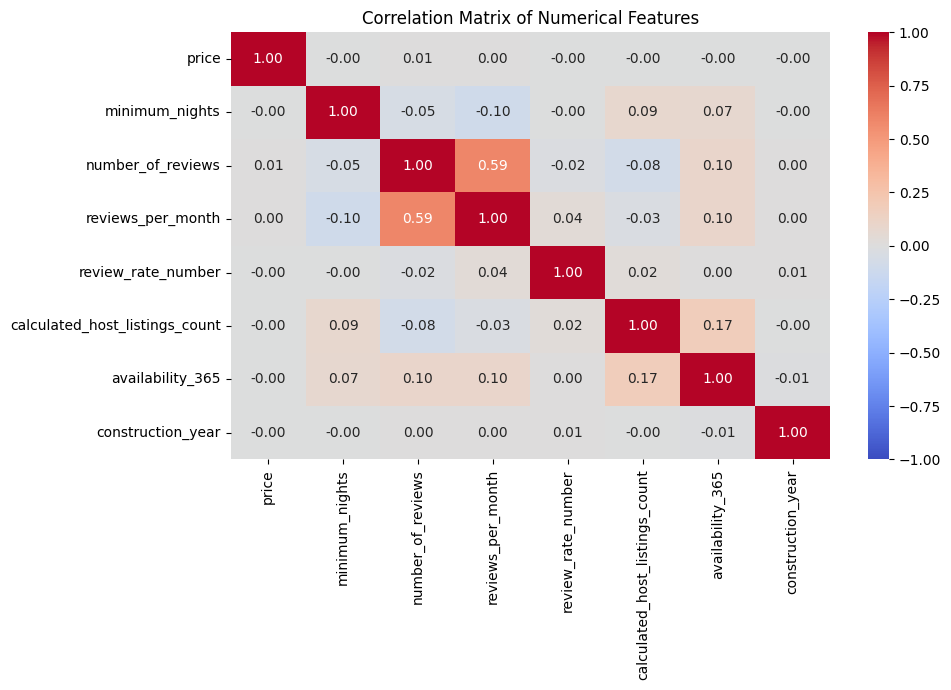

In [ ]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

In [ ]:
# Check how frequently each price occurs
print("Number of unique price values:", df_clean["price"].nunique())

print("\nMost frequent prices:")
display(
    df_clean["price"]
    .value_counts()
    .head(15)
    .rename_axis("price")
    .reset_index(name="listing_count")
)

# Check the percentage of listings at each price boundary
print(
    "\nListings priced at 50:",
    (df_clean["price"] == 50).sum()
)

print(
    "Listings priced at 1200:",
    (df_clean["price"] == 1200).sum()
)

# Check descriptive statistics
display(df_clean["price"].describe().to_frame())

Number of unique price values: 1151

Most frequent prices:


,price,listing_count
0,206.0,135
1,1056.0,131
2,481.0,129
3,833.0,127
4,573.0,126
5,972.0,125
6,138.0,122
7,430.0,120
8,283.0,119
9,406.0,119



Listings priced at 50: 93
Listings priced at 1200: 68


,price
count,101811.000000
mean,625.355580
std,331.672649
min,50.000000
25%,340.000000
50%,625.000000
75%,913.000000
max,1200.000000


In [ ]:
# Select features available for the initial model
feature_cols = [
    "room_type",
    "neighbourhood_group",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "review_rate_number",
    "construction_year",
    "availability_365"
]

target_col = "price"

# Keep only rows with a known target price
model_data = df_clean.dropna(subset=[target_col]).copy()

X = model_data[feature_cols]
y = model_data[target_col]

print("Rows available for modelling:", len(model_data))
print("Number of features:", len(feature_cols))
print("Missing target prices:", y.isna().sum())

display(X.head())

Rows available for modelling: 101811
Number of features: 8
Missing target prices: 0


,room_type,neighbourhood_group,minimum_nights,number_of_reviews,reviews_per_month,review_rate_number,construction_year,availability_365
0,Private room,Brooklyn,10.0,9.0,0.21,4.0,2020.0,286.0
1,Entire home/apt,Manhattan,30.0,45.0,0.38,4.0,2007.0,228.0
2,Private room,Manhattan,3.0,0.0,NaN,5.0,2005.0,352.0
3,Entire home/apt,Brooklyn,30.0,270.0,4.64,4.0,2005.0,322.0
4,Entire home/apt,Manhattan,10.0,9.0,0.10,3.0,2009.0,289.0


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 81448
Testing rows: 20363


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predict the training-set median for every test listing
baseline_prediction = np.full(
    shape=len(y_test),
    fill_value=y_train.median()
)

# Evaluate baseline predictions
baseline_mae = mean_absolute_error(y_test, baseline_prediction)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_prediction)
)

baseline_r2 = r2_score(y_test, baseline_prediction)

print("Baseline median prediction:", round(y_train.median(), 2))
print("Baseline MAE:", round(baseline_mae, 2))
print("Baseline RMSE:", round(baseline_rmse, 2))
print("Baseline R²:", round(baseline_r2, 4))

Baseline median prediction: 625.0
Baseline MAE: 287.14
Baseline RMSE: 331.63
Baseline R²: -0.0


In [ ]:
baseline_results = pd.DataFrame([{
    "Model": "Median Baseline",
    "MAE": baseline_mae,
    "RMSE": baseline_rmse,
    "R2": baseline_r2
}])

display(baseline_results.round(4))

,Model,MAE,RMSE,R2
0,Median Baseline,287.1407,331.6298,-0.0


In [ ]:
print("Total cleaned rows:", len(df_clean))
print("Unique listing IDs:", df_clean["id"].nunique())
print("Repeated listing ID rows:", df_clean["id"].duplicated().sum())

Total cleaned rows: 102058
Unique listing IDs: 102058
Repeated listing ID rows: 0


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Separate numerical and categorical features
numeric_features = [
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "review_rate_number",
    "construction_year",
    "availability_365"
]

categorical_features = [
    "room_type",
    "neighbourhood_group"
]

# Prepare numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Prepare categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing methods
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Create the complete model pipeline
linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

# Train using training data only
linear_model.fit(X_train, y_train)

# Predict prices for the test set
linear_prediction = linear_model.predict(X_test)

# Evaluate performance
linear_mae = mean_absolute_error(y_test, linear_prediction)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_prediction))
linear_r2 = r2_score(y_test, linear_prediction)

print("Linear Regression MAE:", round(linear_mae, 2))
print("Linear Regression RMSE:", round(linear_rmse, 2))
print("Linear Regression R²:", round(linear_r2, 4))

Linear Regression MAE: 287.11
Linear Regression RMSE: 331.63
Linear Regression R²: 0.0


In [ ]:
from sklearn.linear_model import Ridge

# Create the Ridge Regression pipeline
ridge_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", Ridge(alpha=1.0))
])

# Train the model
ridge_model.fit(X_train, y_train)

# Predict prices on the same test set
ridge_prediction = ridge_model.predict(X_test)

# Evaluate predictions
ridge_mae = mean_absolute_error(y_test, ridge_prediction)
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_prediction))
ridge_r2 = r2_score(y_test, ridge_prediction)

print("Ridge Regression MAE:", round(ridge_mae, 2))
print("Ridge Regression RMSE:", round(ridge_rmse, 2))
print("Ridge Regression R²:", round(ridge_r2, 4))

Ridge Regression MAE: 287.11
Ridge Regression RMSE: 331.63
Ridge Regression R²: 0.0


In [ ]:
model_comparison = pd.DataFrame([
    {
        "Model": "Median Baseline",
        "MAE": baseline_mae,
        "RMSE": baseline_rmse,
        "R2": baseline_r2
    },
    {
        "Model": "Linear Regression",
        "MAE": linear_mae,
        "RMSE": linear_rmse,
        "R2": linear_r2
    },
    {
        "Model": "Ridge Regression",
        "MAE": ridge_mae,
        "RMSE": ridge_rmse,
        "R2": ridge_r2
    }
])

display(
    model_comparison
    .sort_values("MAE")
    .round(4)
    .reset_index(drop=True)
)

,Model,MAE,RMSE,R2
0,Linear Regression,287.1105,331.6255,0.0
1,Ridge Regression,287.1106,331.6256,0.0
2,Median Baseline,287.1407,331.6298,-0.0


In [ ]:
print("Total cleaned rows:", len(df_clean))
print("Unique listing IDs:", df_clean["id"].nunique())
print("Repeated listing ID rows:", df_clean["id"].duplicated().sum())

Total cleaned rows: 102058
Unique listing IDs: 102058
Repeated listing ID rows: 0


In [ ]:
# Create a copy of training and test data
train_eval = X_train.copy()
test_eval = X_test.copy()

train_eval["price"] = y_train

# Handle missing category labels consistently
category_cols = ["room_type", "neighbourhood_group"]

for col in category_cols:
    train_eval[col] = train_eval[col].fillna("Unknown")
    test_eval[col] = test_eval[col].fillna("Unknown")

# Calculate median prices using training data only
group_medians = train_eval.groupby(category_cols)["price"].median()
training_median = y_train.median()

# Predict using the room type + neighbourhood combination
test_keys = pd.MultiIndex.from_frame(test_eval[category_cols])

category_prediction = group_medians.reindex(test_keys).to_numpy()

# For combinations not found in training, use the training median
category_prediction = np.where(
    pd.isna(category_prediction),
    training_median,
    category_prediction
)

# Evaluate the category-based baseline
category_mae = mean_absolute_error(y_test, category_prediction)
category_rmse = np.sqrt(
    mean_squared_error(y_test, category_prediction)
)
category_r2 = r2_score(y_test, category_prediction)

print("Category Median Baseline MAE:", round(category_mae, 2))
print("Category Median Baseline RMSE:", round(category_rmse, 2))
print("Category Median Baseline R²:", round(category_r2, 4))

Category Median Baseline MAE: 287.14
Category Median Baseline RMSE: 331.68
Category Median Baseline R²: -0.0003


In [ ]:
model_comparison = pd.concat([
    model_comparison,
    pd.DataFrame([{
        "Model": "Room Type + Neighbourhood Median",
        "MAE": category_mae,
        "RMSE": category_rmse,
        "R2": category_r2
    }])
], ignore_index=True)

display(
    model_comparison
    .sort_values("MAE")
    .round(4)
    .reset_index(drop=True)
)

,Model,MAE,RMSE,R2
0,Linear Regression,287.1105,331.6255,0.0000
1,Ridge Regression,287.1106,331.6256,0.0000
2,Room Type + Neighbourhood Median,287.1375,331.6794,-0.0003
3,Median Baseline,287.1407,331.6298,-0.0000


In [ ]:
categorical_cols = [
    "room_type",
    "neighbourhood_group",
    "cancellation_policy",
    "instant_bookable"
]

for col in categorical_cols:
    print(f"\n--- {col} ---")

    summary = (
        df_clean.groupby(col, dropna=False)["price"]
        .agg(["count", "median", "mean"])
        .sort_values("median", ascending=False)
    )

    display(summary.round(2))


--- room_type ---


,count,median,mean
room_type,,,
Shared room,2200,651.5,634.83
Hotel room,115,643.0,666.39
Entire home/apt,53296,624.0,625.24
Private room,46200,623.0,624.94



--- neighbourhood_group ---


,count,median,mean
neighbourhood_group,,,
NaN,28,661.0,658.36
Bronx,2687,632.0,627.76
Staten Island,946,628.0,623.99
Queens,13164,628.0,630.22
Brooklyn,41538,626.0,626.50
Manhattan,43448,621.0,622.65



--- cancellation_policy ---


,count,median,mean
cancellation_policy,,,
NaN,71,693.0,645.14
flexible,33808,626.0,626.23
strict,33847,625.0,624.59
moderate,34085,622.0,625.21



--- instant_bookable ---


,count,median,mean
instant_bookable,,,
NaN,100,661.0,633.83
0.0,51066,626.0,625.18
1.0,50645,623.0,625.52


In [ ]:
categorical_cols = [
    "host_identity_verified",
    "neighbourhood",
    "country",
    "country_code",
    "name"
]

for col in categorical_cols:
    print(f"\n--- {col} ---")

    summary = (
        df_clean.groupby(col, dropna=False)["price"]
        .agg(["count", "median", "mean"])
        .sort_values("count", ascending=False)
    )

    display(summary.head(15).round(2))


--- host_identity_verified ---


,count,median,mean
host_identity_verified,,,
unconfirmed,50831,626.0,626.79
verified,50695,623.0,623.83
NaN,285,656.0,640.87



--- neighbourhood ---


,count,median,mean
neighbourhood,,,
Bedford-Stuyvesant,7882,621.0,623.21
Williamsburg,7713,626.0,625.39
Harlem,5431,620.0,626.98
Bushwick,4940,640.0,633.16
Hell's Kitchen,3945,619.0,621.09
Upper West Side,3834,619.0,616.66
Upper East Side,3644,629.0,619.13
East Village,3459,616.0,618.00
Midtown,3347,609.0,609.81



--- country ---


,count,median,mean
country,,,
United States,101284,624.0,625.45
NaN,527,627.0,608.09



--- country_code ---


,count,median,mean
country_code,,,
US,101685,624.0,625.35
NaN,126,645.5,630.01



--- name ---


,count,median,mean
name,,,
NaN,267,597.0,620.84
Home away from home,32,654.0,647.12
Hillside Hotel,30,736.0,647.30
Water View King Bed Hotel Room,29,656.0,594.45
Brooklyn Apartment,27,570.0,512.30
New york Multi-unit building,27,664.0,668.04
Private Room,23,535.0,578.65
Cozy Brooklyn Apartment,19,636.0,666.37
Private room in Brooklyn,19,605.0,601.95


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

numeric_features = [
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "review_rate_number",
    "construction_year",
    "availability_365"
]

categorical_features = [
    "room_type",
    "neighbourhood_group",
    "neighbourhood",
    "cancellation_policy",
    "host_identity_verified",
    "instant_bookable"
]

feature_cols = numeric_features + categorical_features

model_data = df_clean.dropna(subset=["price"]).copy()

X = model_data[feature_cols]
y = model_data["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

neighbourhood_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge(alpha=10.0))
])

neighbourhood_model.fit(X_train, y_train)
predictions = neighbourhood_model.predict(X_test)

print("MAE:", round(mean_absolute_error(y_test, predictions), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, predictions)), 4))
print("R2:", round(r2_score(y_test, predictions), 4))

MAE: 287.0803
RMSE: 331.7642
R2: -0.0008


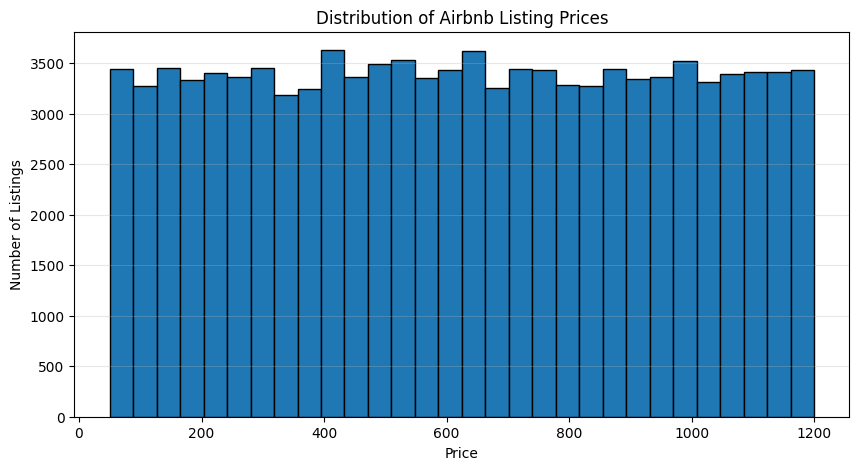


Price statistics:
count    101811.00
mean        625.36
std         331.67
min          50.00
25%         340.00
50%         625.00
75%         913.00
max        1200.00
Name: price, dtype: float64

Unique price values: 1151

Percentage of listings priced at 50: 0.09 %
Percentage of listings priced at 1200: 0.07 %


In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    df_clean["price"].dropna(),
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Airbnb Listing Prices")
plt.xlabel("Price")
plt.ylabel("Number of Listings")
plt.grid(axis="y", alpha=0.3)
plt.show()

print("\nPrice statistics:")
print(df_clean["price"].describe().round(2))

print(
    "\nUnique price values:",
    df_clean["price"].nunique()
)

print(
    "\nPercentage of listings priced at 50:",
    round((df_clean["price"] == 50).mean() * 100, 2), "%"
)

print(
    "Percentage of listings priced at 1200:",
    round((df_clean["price"] == 1200).mean() * 100, 2), "%"
)

In [ ]:
# Count how many listings have each exact price
price_counts = df_clean["price"].value_counts().sort_index()

# Calculate descriptive statistics of the price frequencies
print("Number of distinct prices:", len(price_counts))
print("Mean listings per price:", round(price_counts.mean(), 2))
print("Median listings per price:", price_counts.median())
print("Standard deviation:", round(price_counts.std(), 2))

# Display the 15 most common exact prices
print("\nMost common exact prices:")
display(
    df_clean["price"]
    .value_counts()
    .head(15)
    .rename_axis("price")
    .reset_index(name="listing_count")
)

# Show the spread of listing counts across exact prices
print("\nDistribution of counts per price:")
display(price_counts.describe().round(2))

Number of distinct prices: 1151
Mean listings per price: 88.45
Median listings per price: 88.0
Standard deviation: 12.73

Most common exact prices:


,price,listing_count
0,206.0,135
1,1056.0,131
2,481.0,129
3,833.0,127
4,573.0,126
5,972.0,125
6,138.0,122
7,430.0,120
8,283.0,119
9,406.0,119



Distribution of counts per price:


,count
count,1151.00
mean,88.45
std,12.73
min,52.00
25%,80.00
50%,88.00
75%,97.00
max,135.00


In [ ]:
numeric_cols = [
    "price",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "review_rate_number",
    "construction_year",
    "availability_365",
    "calculated_host_listings_count"
]

correlation = (
    df_clean[numeric_cols]
    .corr(numeric_only=True)["price"]
    .drop("price")
    .sort_values()
)

print("Correlation of numeric features with price:")
display(correlation.to_frame(name="correlation").round(4))


Correlation of numeric features with price:


,correlation
review_rate_number,-0.0046
construction_year,-0.0037
minimum_nights,-0.0027
availability_365,-0.0016
calculated_host_listings_count,-0.0001
reviews_per_month,0.0040
number_of_reviews,0.0051


In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
import pandas as pd

cluster_features = [
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "review_rate_number",
    "construction_year",
    "availability_365",
    "calculated_host_listings_count"
]

# Select the features for clustering
X_cluster = df_clean[cluster_features].copy()

# Replace infinite values with missing values
X_cluster = X_cluster.replace([float("inf"), float("-inf")], float("nan"))

# Fill missing values using each column's median
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X_cluster)

# Standardize features to comparable scales
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

print("Original rows:", len(X_cluster))
print("Rows prepared:", X_scaled.shape[0])
print("Features used:", X_scaled.shape[1])
print("Missing values after imputation:", pd.isna(X_scaled).sum())

Original rows: 102058
Rows prepared: 102058
Features used: 7
Missing values after imputation: 0


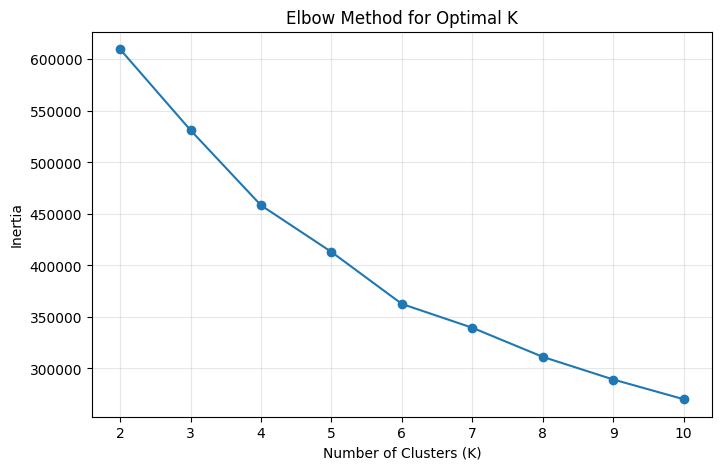

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia_values = []
k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    inertia_values.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia_values, marker="o")
plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
from sklearn.cluster import KMeans
import pandas as pd

# Create the K-Means model with 4 clusters
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Train the model and assign each listing to a cluster
cluster_labels = kmeans.fit_predict(X_scaled)

# Add cluster labels to a copy of the cleaned dataset
df_clustered = df_clean.copy()
df_clustered["cluster"] = cluster_labels

# Count listings in each cluster
print("Number of listings in each cluster:")
display(
    df_clustered["cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("cluster")
    .reset_index(name="listing_count")
)

Number of listings in each cluster:


,cluster,listing_count
0,0,31112
1,1,14724
2,2,54508
3,3,1714


In [ ]:
cluster_summary = (
    df_clustered.groupby("cluster")
    .agg(
        listing_count=("id", "count"),
        median_price=("price", "median"),
        median_minimum_nights=("minimum_nights", "median"),
        median_reviews=("number_of_reviews", "median"),
        median_reviews_per_month=("reviews_per_month", "median"),
        median_rating=("review_rate_number", "median"),
        median_availability=("availability_365", "median"),
        median_host_listings=("calculated_host_listings_count", "median")
    )
)

display(cluster_summary.round(2))

,listing_count,median_price,median_minimum_nights,median_reviews,median_reviews_per_month,median_rating,median_availability,median_host_listings
cluster,,,,,,,,
0,31112,620.0,3.0,6.0,0.62,3.0,299.0,2.0
1,14724,632.0,2.0,100.0,3.61,3.0,137.0,1.0
2,54508,624.0,3.0,4.0,0.44,3.0,7.0,1.0
3,1714,644.0,30.0,2.0,0.39,4.0,273.0,208.0


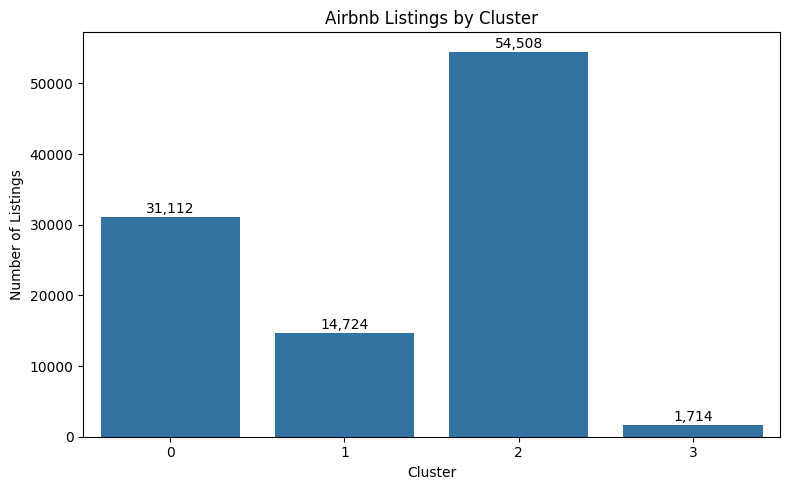

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

cluster_counts = (
    df_clustered["cluster"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=cluster_counts.index,
    y=cluster_counts.values
)

plt.title("Airbnb Listings by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Listings")

for i, count in enumerate(cluster_counts.values):
    plt.text(i, count + 500, f"{count:,}", ha="center")

plt.tight_layout()
plt.show()

In [ ]:
# Count listings by cluster and room type
room_cluster = pd.crosstab(
    df_clustered["cluster"],
    df_clustered["room_type"]
)

print("Listing counts by cluster and room type:")
display(room_cluster)

# Convert counts into percentages within each cluster
room_cluster_pct = pd.crosstab(
    df_clustered["cluster"],
    df_clustered["room_type"],
    normalize="index"
) * 100

print("Room type percentages within each cluster:")
display(room_cluster_pct.round(2))

Listing counts by cluster and room type:


room_type,Entire home/apt,Hotel room,Private room,Shared room
cluster,,,,
0,16220,57,13923,912
1,7692,25,6763,244
2,28155,33,25268,1052
3,1362,0,352,0


Room type percentages within each cluster:


room_type,Entire home/apt,Hotel room,Private room,Shared room
cluster,,,,
0,52.13,0.18,44.75,2.93
1,52.24,0.17,45.93,1.66
2,51.65,0.06,46.36,1.93
3,79.46,0.00,20.54,0.00


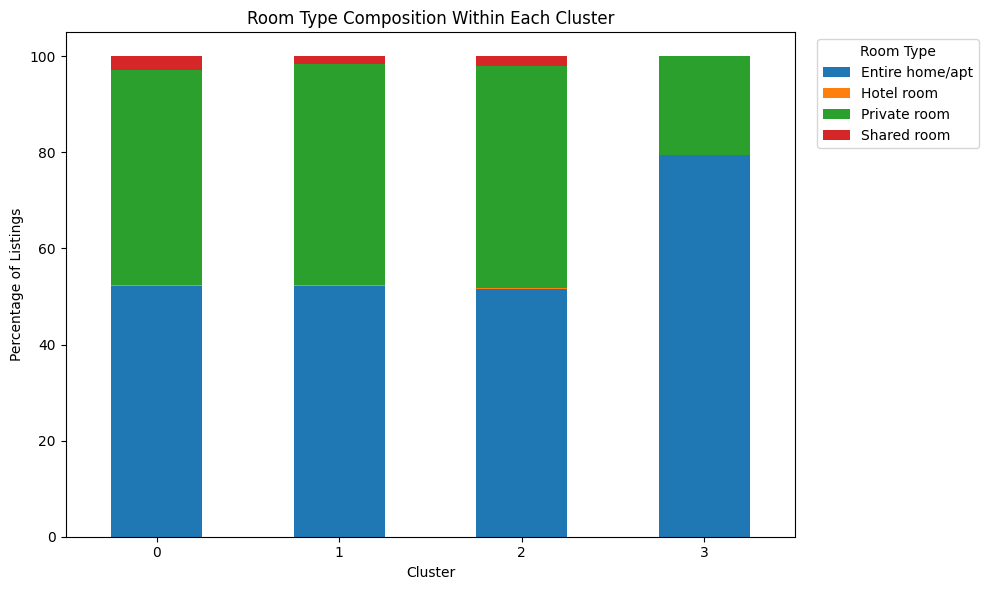

In [ ]:
import matplotlib.pyplot as plt

room_cluster_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Room Type Composition Within Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Percentage of Listings")
plt.xticks(rotation=0)
plt.legend(
    title="Room Type",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

In [ ]:
# Count listings by cluster and neighbourhood group
neighbourhood_counts = pd.crosstab(
    df_clustered["cluster"],
    df_clustered["neighbourhood_group"]
)

print("Neighbourhood counts by cluster:")
display(neighbourhood_counts)

# Calculate percentages within each cluster
neighbourhood_pct = pd.crosstab(
    df_clustered["cluster"],
    df_clustered["neighbourhood_group"],
    normalize="index"
) * 100

print("Neighbourhood percentages within each cluster:")
display(neighbourhood_pct.round(2))

Neighbourhood counts by cluster:


neighbourhood_group,Bronx,Brooklyn,Manhattan,Queens,Staten Island
cluster,,,,,
0,1110,11530,13416,4608,443
1,511,6219,5335,2462,185
2,1073,23816,23410,5876,321
3,0,66,1397,251,0


Neighbourhood percentages within each cluster:


neighbourhood_group,Bronx,Brooklyn,Manhattan,Queens,Staten Island
cluster,,,,,
0,3.57,37.07,43.13,14.81,1.42
1,3.47,42.27,36.26,16.73,1.26
2,1.97,43.70,42.96,10.78,0.59
3,0.00,3.85,81.51,14.64,0.00


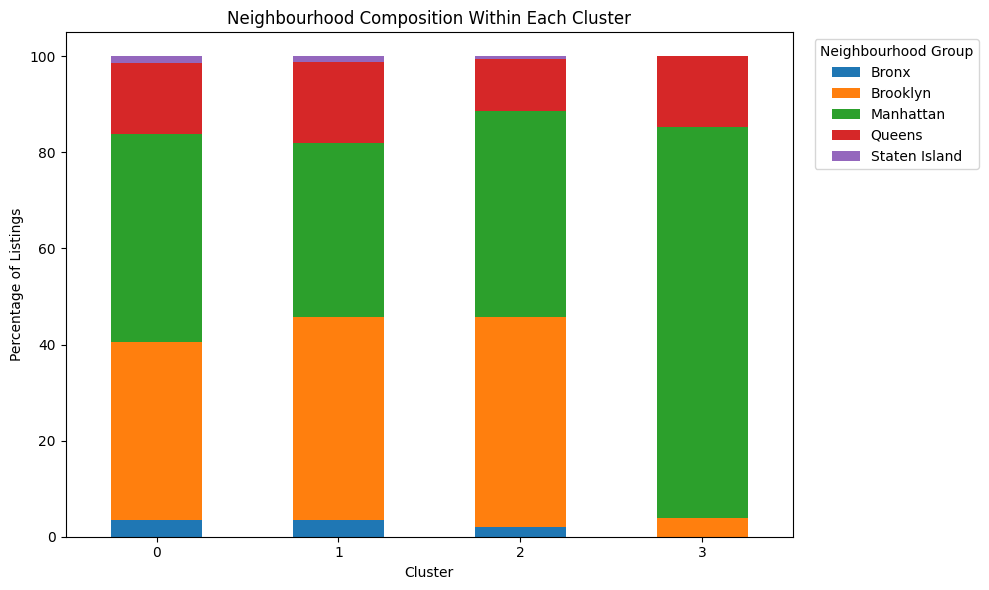

In [ ]:
import matplotlib.pyplot as plt

neighbourhood_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Neighbourhood Composition Within Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Percentage of Listings")
plt.xticks(rotation=0)
plt.legend(
    title="Neighbourhood Group",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import silhouette_score
import numpy as np

# Select a reproducible sample of 5,000 listings
rng = np.random.RandomState(42)
sample_indices = rng.choice(
    len(X_scaled),
    size=5000,
    replace=False
)

X_sample = X_scaled[sample_indices]
labels_sample = cluster_labels[sample_indices]

# Calculate cluster quality
score = silhouette_score(
    X_sample,
    labels_sample
)

print("Silhouette Score:", round(score, 4))

Silhouette Score: 0.2344


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd
import numpy as np

results = []

# Use the same sample for a fair comparison
for k in [3, 4, 5, 6]:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_sample)

    score = silhouette_score(
        X_sample,
        labels
    )

    results.append({
        "K": k,
        "Inertia": round(model.inertia_, 2),
        "Silhouette Score": round(score, 4)
    })

results_df = pd.DataFrame(results)
display(results_df)

,K,Inertia,Silhouette Score
0,3,22308.44,0.2929
1,4,18746.84,0.2342
2,5,16392.99,0.2111
3,6,14908.11,0.2061


In [ ]:
from sklearn.cluster import KMeans
import pandas as pd

# Create a new model with 3 clusters
kmeans_3 = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Fit the model on all prepared listings
labels_3 = kmeans_3.fit_predict(X_scaled)

# Store the new cluster labels separately
df_clustered_3 = df_clean.copy()
df_clustered_3["cluster"] = labels_3

# Count listings in each cluster
print("Listings in each cluster:")
display(
    df_clustered_3["cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("cluster")
    .reset_index(name="listing_count")
)

Listings in each cluster:


,cluster,listing_count
0,0,15201
1,1,29517
2,2,57340


In [ ]:
cluster_summary_3 = (
    df_clustered_3.groupby("cluster")
    .agg(
        listing_count=("id", "count"),
        median_price=("price", "median"),
        median_minimum_nights=("minimum_nights", "median"),
        median_reviews=("number_of_reviews", "median"),
        median_reviews_per_month=("reviews_per_month", "median"),
        median_rating=("review_rate_number", "median"),
        median_availability=("availability_365", "median"),
        median_host_listings=("calculated_host_listings_count", "median")
    )
)

display(cluster_summary_3.round(2))

,listing_count,median_price,median_minimum_nights,median_reviews,median_reviews_per_month,median_rating,median_availability,median_host_listings
cluster,,,,,,,,
0,15201,631.0,2.0,98.0,3.57,3.0,143.0,1.0
1,29517,621.0,3.0,5.0,0.58,3.0,309.0,2.0
2,57340,624.0,3.0,4.0,0.45,3.0,11.0,1.0


In [ ]:
room_cluster_3_pct = pd.crosstab(
    df_clustered_3["cluster"],
    df_clustered_3["room_type"],
    normalize="index"
) * 100

display(room_cluster_3_pct.round(2))

room_type,Entire home/apt,Hotel room,Private room,Shared room
cluster,,,,
0,52.42,0.16,45.75,1.66
1,54.36,0.19,42.58,2.88
2,51.30,0.06,46.71,1.93


In [ ]:
neighbourhood_3_pct = pd.crosstab(
    df_clustered_3["cluster"],
    df_clustered_3["neighbourhood_group"],
    normalize="index"
) * 100

display(neighbourhood_3_pct.round(2))


neighbourhood_group,Bronx,Brooklyn,Manhattan,Queens,Staten Island
cluster,,,,,
0,3.43,42.16,36.24,16.90,1.28
1,3.22,34.51,46.68,14.27,1.32
2,2.14,43.68,42.35,11.20,0.64


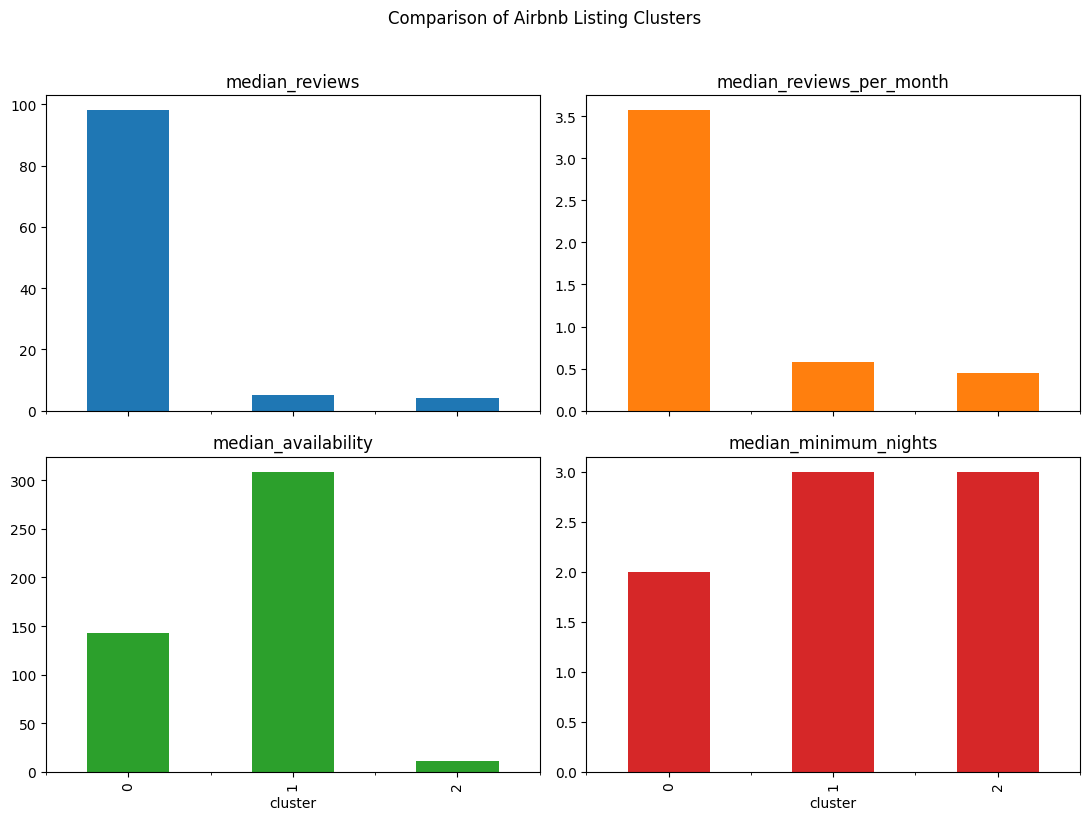

In [ ]:
import matplotlib.pyplot as plt

profile_cols = [
    "median_reviews",
    "median_reviews_per_month",
    "median_availability",
    "median_minimum_nights"
]

cluster_summary_3[profile_cols].plot(
    kind="bar",
    subplots=True,
    layout=(2, 2),
    figsize=(11, 8),
    legend=False
)

plt.suptitle("Comparison of Airbnb Listing Clusters", y=1.02)
plt.tight_layout()
plt.show()

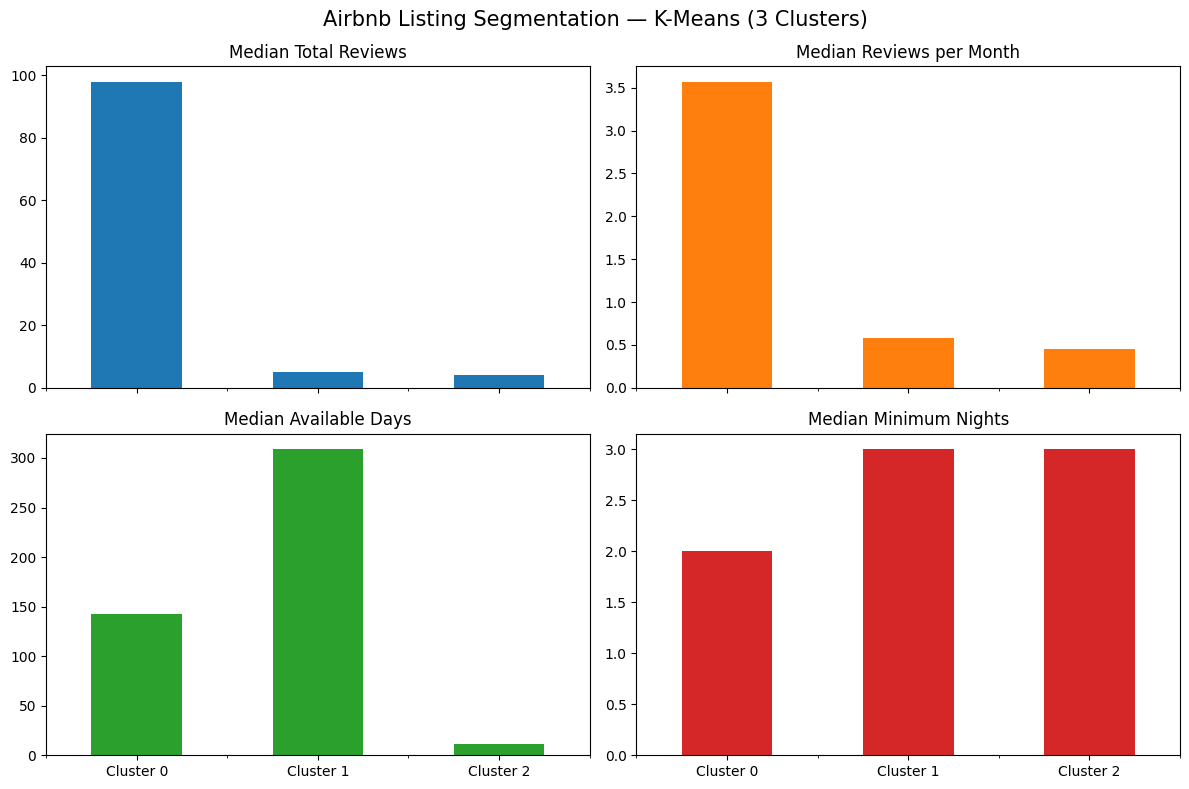

In [ ]:
import matplotlib.pyplot as plt

plot_data = cluster_summary_3[
    [
        "median_reviews",
        "median_reviews_per_month",
        "median_availability",
        "median_minimum_nights"
    ]
].copy()

plot_data.index = [
    f"Cluster {i}" for i in plot_data.index
]

plot_data.columns = [
    "Median Total Reviews",
    "Median Reviews per Month",
    "Median Available Days",
    "Median Minimum Nights"
]

axes = plot_data.plot(
    kind="bar",
    subplots=True,
    layout=(2, 2),
    figsize=(12, 8),
    legend=False,
    rot=0
)

plt.suptitle(
    "Airbnb Listing Segmentation — K-Means (3 Clusters)",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import silhouette_score

sample_size = min(5000, len(X_scaled))

silhouette = silhouette_score(
    X_scaled,
    df_clustered_3["cluster"],
    sample_size=sample_size,
    random_state=42
)

print("Number of clusters:", df_clustered_3["cluster"].nunique())
print("Silhouette Score:", round(silhouette, 4))

Number of clusters: 3
Silhouette Score: 0.241


### K-Means Clustering Evaluation

K-Means clustering was applied to segment Airbnb listings using seven numerical features related to reviews, availability, minimum nights, ratings, construction year, and host listing counts. A three-cluster solution was selected for further interpretation.

The silhouette score was **0.241**, indicating moderate-to-weak separation between clusters and some overlap among listings. Despite this limitation, the clusters revealed differences in review activity and listing availability.

Cluster 0 represents listings with higher review activity, Cluster 1 contains listings with high availability and lower review activity, and Cluster 2 contains listings with low availability and lower review activity. These findings are exploratory and should not be interpreted as direct measures of demand.

In [ ]:
final_cluster_summary = (
    df_clustered_3.groupby("cluster")
    .agg(
        listing_count=("id", "count"),
        median_price=("price", "median"),
        median_reviews=("number_of_reviews", "median"),
        median_reviews_per_month=("reviews_per_month", "median"),
        median_availability=("availability_365", "median"),
        median_minimum_nights=("minimum_nights", "median")
    )
    .reset_index()
)

final_cluster_summary["listing_percentage"] = (
    final_cluster_summary["listing_count"]
    / len(df_clustered_3) * 100
).round(2)

display(final_cluster_summary.round(2))

,cluster,listing_count,median_price,median_reviews,median_reviews_per_month,median_availability,median_minimum_nights,listing_percentage
0,0,15201,631.0,98.0,3.57,143.0,2.0,14.89
1,1,29517,621.0,5.0,0.58,309.0,3.0,28.92
2,2,57340,624.0,4.0,0.45,11.0,3.0,56.18


### Airbnb Listing Segmentation Using K-Means

A K-Means clustering model was applied to 102,058 Airbnb listings using seven numerical features related to reviews, ratings, availability, minimum nights, construction year, and host listing counts. The dataset was divided into three clusters.

**Cluster 0 (14.89%) — High Review Activity:** This group contains 15,201 listings, with median total reviews of 98 and median reviews per month of 3.57. Median availability is 143 days.

**Cluster 1 (28.92%) — High Availability:** This group contains 29,517 listings, with median total reviews of 5 and median availability of 309 days.

**Cluster 2 (56.18%) — Low Availability:** This group contains 57,340 listings, with median total reviews of 4 and median availability of 11 days.

The median prices across the clusters are relatively similar, ranging from 621 to 631 dataset price units. The silhouette score of 0.241 indicates that the clusters overlap, so the results should be interpreted as exploratory segments rather than sharply separated categories.

Overall, the clustering reveals differences in review activity and calendar availability. Additional data validation and business context are required before drawing conclusions about customer demand or listing performance.
